In [1053]:
import pandas as pd

# load csv into dataframe
df = pd.read_csv('worklifebalance.csv')

df.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,AverageOTperWeek,PercentSalaryHikeLastYear,PerformanceRating,HighPerformer,RelationshipSatisfaction,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,Attrition
0,41,Travel_Rarely,1102,Sales,1,College,Life Sciences,Medium,Female,94,...,12,11,Excellent,No,Low,8,0,Poor,6,Yes
1,49,Travel_Frequently,279,Research & Development,8,Below College,Life Sciences,High,Male,61,...,3,23,Outstanding,No,Very high,10,3,Excellent,10,No
2,37,Travel_Rarely,1373,Research & Development,2,College,Other,Very High,Male,92,...,10,15,Excellent,No,Medium,7,3,Excellent,0,Yes
3,33,Travel_Frequently,1392,Research & Development,3,Masters,Life Sciences,Very High,Female,56,...,14,11,Excellent,No,High,8,3,Excellent,8,No
4,27,Travel_Rarely,591,Research & Development,2,Below College,Medical,Low,Male,40,...,5,12,Excellent,No,Very high,6,3,Excellent,2,No


In [1054]:
# Select 6 columns to be used for analysis and prediction

df_selected = df[["WorkLifeBalance", 
                  "MonthlyIncome", 
                  "JobSatisfaction", 
                  "RelationshipSatisfaction", 
                  "TrainingTimesLastYear", 
                  "Attrition"]]

df_selected.head()

,WorkLifeBalance,MonthlyIncome,JobSatisfaction,RelationshipSatisfaction,TrainingTimesLastYear,Attrition
0,Poor,5993,Very high,Low,0,Yes
1,Excellent,5130,Medium,Very high,3,No
2,Excellent,2090,High,Medium,3,Yes
3,Excellent,2909,High,High,3,No
4,Excellent,3468,Medium,Very high,3,No


In [1055]:
# Count duplicate rows in the selected dataframe

duplicates = df_selected.duplicated().sum()

print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 0


In [1056]:
# Count missing values

missing = df_selected.isna().sum()
empty = df_selected.eq("").sum()

pd.DataFrame({
    "Missing": missing,
    "Empty String": empty
})

,Missing,Empty String
WorkLifeBalance,0,0
MonthlyIncome,0,0
JobSatisfaction,0,0
RelationshipSatisfaction,0,0
TrainingTimesLastYear,0,0
Attrition,0,0


In [1057]:
# Ensure consistent data formatting and representation (1 / 2)
# View and count unique values in each column of the dataset

for col in df_selected.columns.drop("MonthlyIncome"):
    print(df_selected[col].value_counts(dropna=False), "\n")

WorkLifeBalance
Excellent      120
Good            51
Outstanding     19
Poor            10
Name: count, dtype: int64 

JobSatisfaction
Very high    64
High         62
Medium       38
Low          36
Name: count, dtype: int64 

RelationshipSatisfaction
Very high    73
High         63
Low          35
Medium       29
Name: count, dtype: int64 

TrainingTimesLastYear
3    72
2    71
5    18
1    14
4    11
0     7
6     7
Name: count, dtype: int64 

Attrition
No     170
Yes     30
Name: count, dtype: int64 



In [1058]:
# Ensure consistent data formatting and representation (2 / 2)
# Check for negative values and non-integer values in the "MonthlyIncome" column

print("Negative values:", (df_selected["MonthlyIncome"] < 0).sum())
print("Non-integers:", (df_selected["MonthlyIncome"] % 1 != 0).sum())

Negative values: 0
Non-integers: 0


In [1059]:
# Encode categorical values for decision tree model

df_encoded = df_selected.copy()

df_encoded["WorkLifeBalance"] = df_encoded["WorkLifeBalance"].map({
    "Poor": 1,
    "Good": 2,
    "Excellent": 3,
    "Outstanding": 4
})

df_encoded["JobSatisfaction"] = df_encoded["JobSatisfaction"].map({
    "Low": 1,
    "Medium": 2,
    "High": 3,
    "Very high": 4
})

df_encoded["RelationshipSatisfaction"] = df_encoded["RelationshipSatisfaction"].map({
    "Low": 1,
    "Medium": 2,
    "High": 3,
    "Very high": 4
})

df_encoded["Attrition"] = df_encoded["Attrition"].map({
    "No": 0,
    "Yes": 1
})

df_encoded.head()

,WorkLifeBalance,MonthlyIncome,JobSatisfaction,RelationshipSatisfaction,TrainingTimesLastYear,Attrition
0,1,5993,4,1,0,1
1,3,5130,2,4,3,0
2,3,2090,3,2,3,1
3,3,2909,3,3,3,0
4,3,3468,2,4,3,0


In [1060]:
from sklearn.model_selection import train_test_split

# Split df_encoded into inputs and target variable
inputs = df_encoded.drop("Attrition", axis=1)
target = df_encoded["Attrition"]

# Split the dataset into training (80%) and testing sets (20%) 
inputs_train, inputs_test, target_train, target_test = train_test_split(inputs, 
                                                                        target, 
                                                                        test_size=0.2, 
                                                                        random_state=42,
                                                                        stratify=target)

In [1061]:
from sklearn import tree

# Train a decision tree model using the training data

model = tree.DecisionTreeClassifier(class_weight="balanced", random_state=42)
model.fit(inputs_train, target_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are 

In [1062]:
from sklearn.metrics import classification_report

predictions = model.predict(inputs_test)

print(classification_report(target_test, predictions))

              precision    recall  f1-score   support

           0       0.91      0.85      0.88        34
           1       0.38      0.50      0.43         6

    accuracy                           0.80        40
   macro avg       0.64      0.68      0.65        40
weighted avg       0.83      0.80      0.81        40



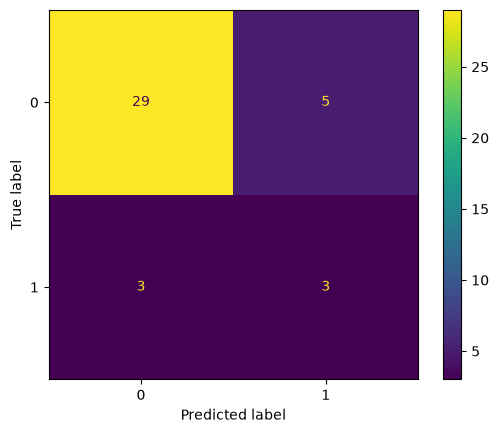

In [1063]:
# Display confusion matrix and classification report for the model's predictions on the test set
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# predictions
y_pred = model.predict(inputs_test)

# confusion matrix
cm = confusion_matrix(target_test, y_pred)

# display
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.show()


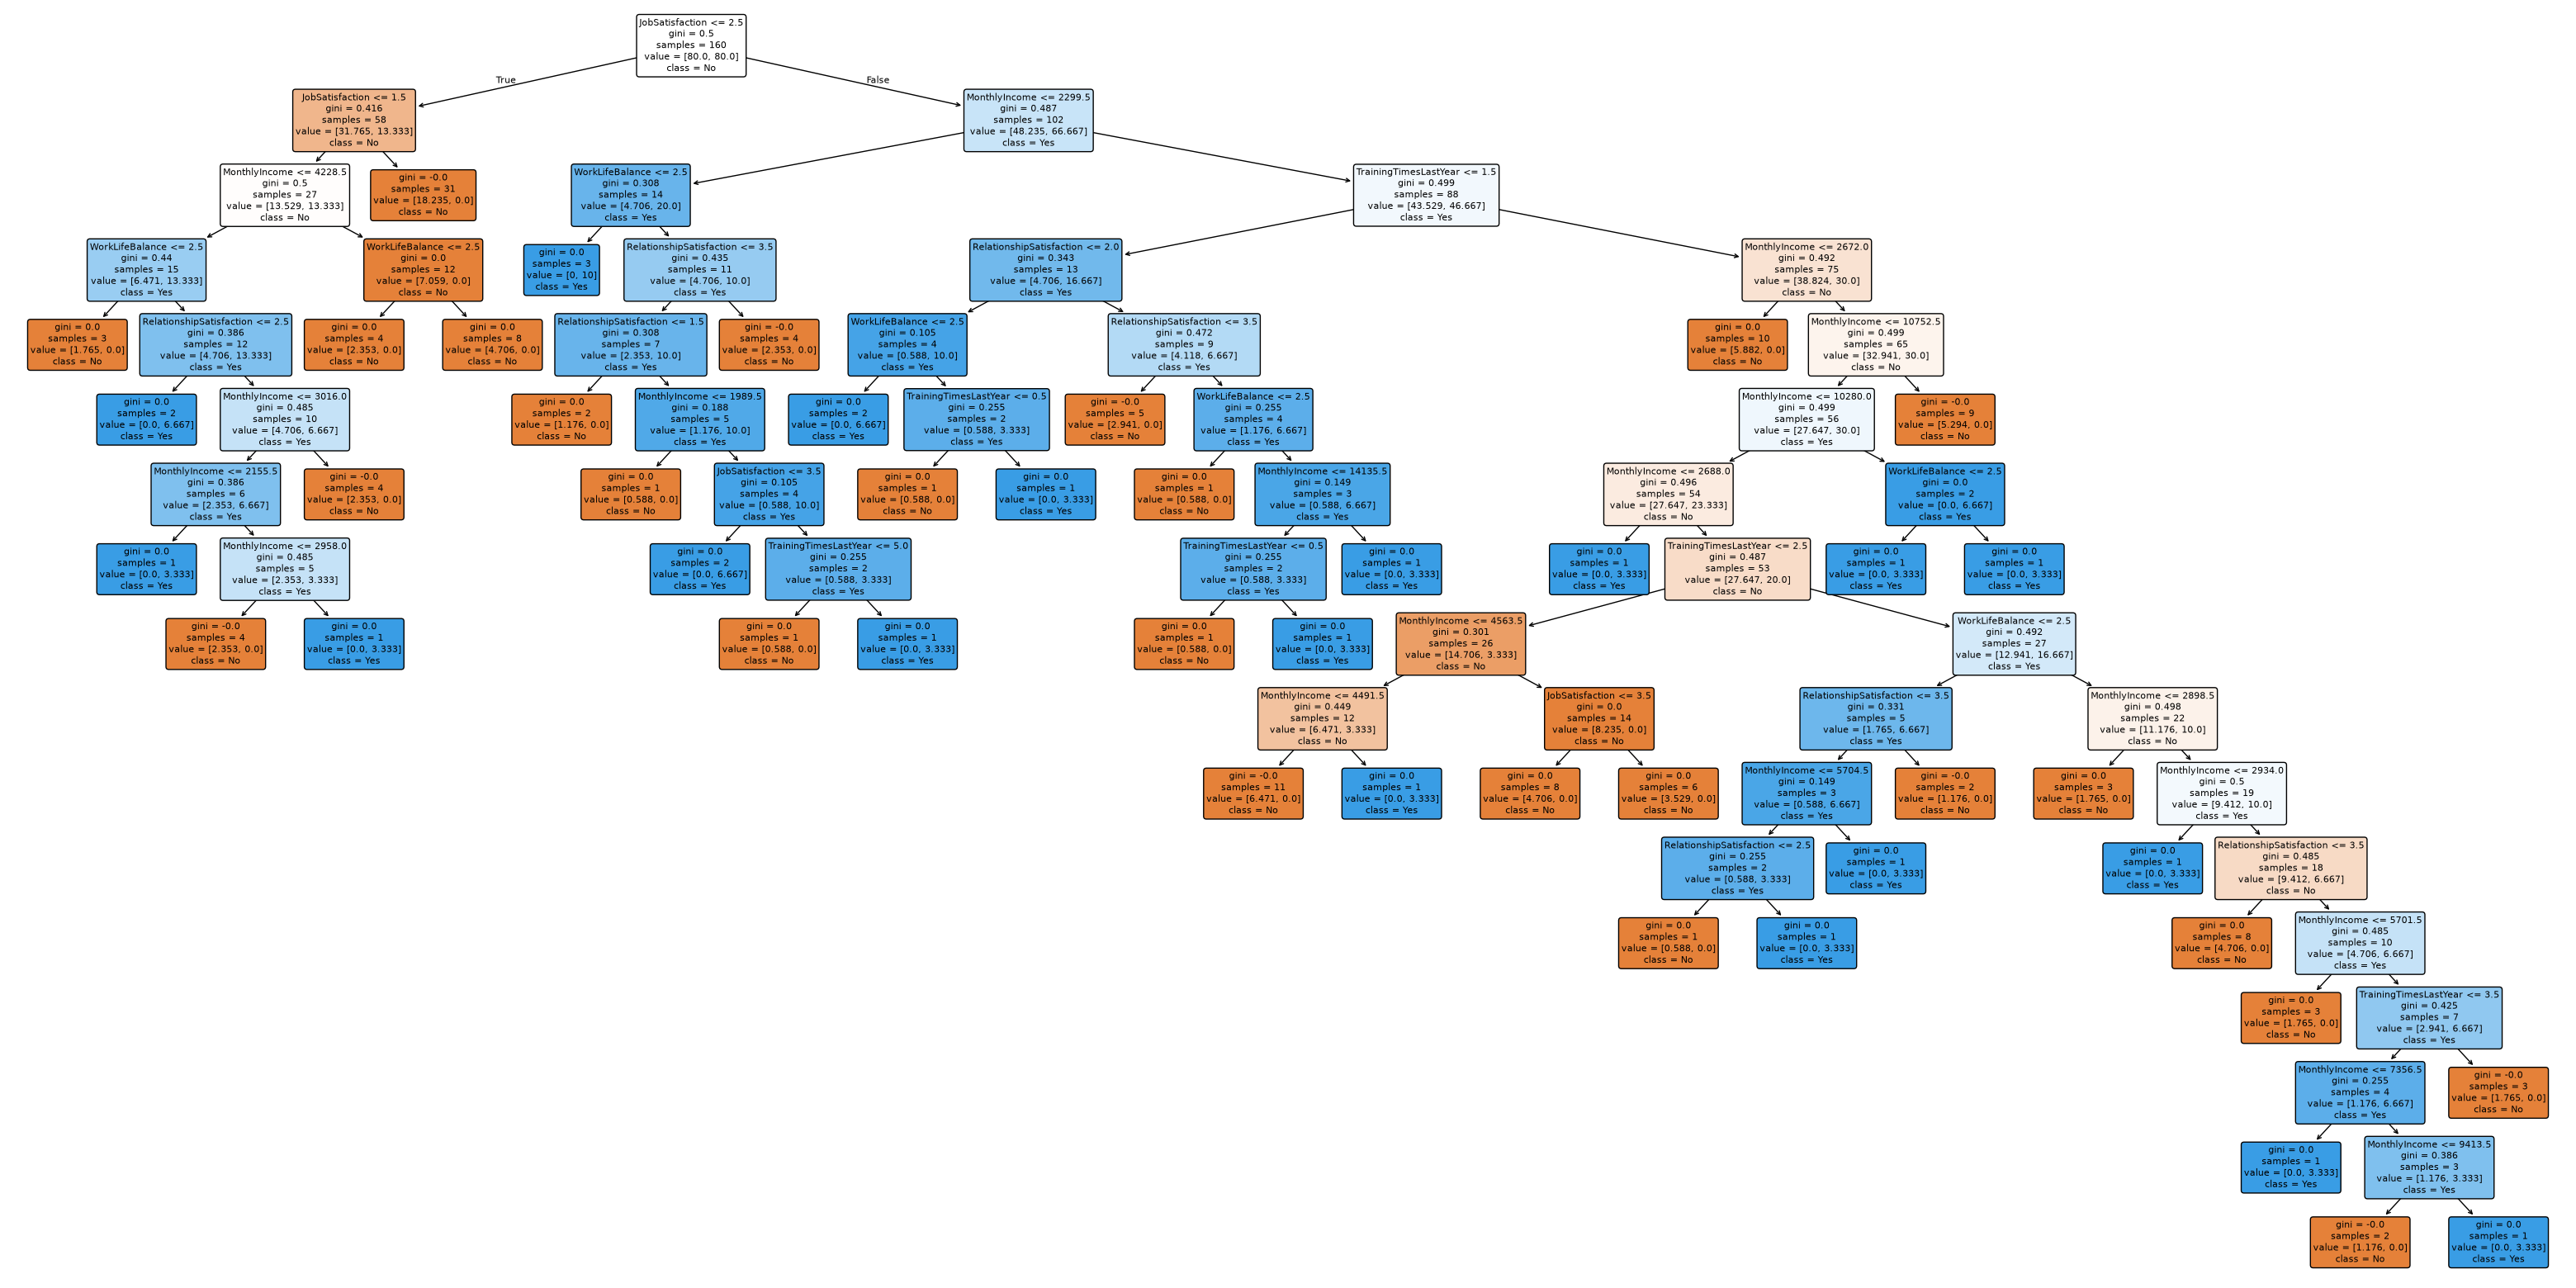

In [1064]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(40, 20))

plot_tree(
    model,
    feature_names=inputs.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()